# CDS 303 - Project 0: Dataset Exploration

# Team members 
-Donghyeok Kim
-Dongjun Lee

## Dataset
- Name: Inside Airbnb – New York City Listings (merged with neighborhood-level ACS data)
- Source: Inside Airbnb (http://insideairbnb.com/get-the-data/); neighborhood (NTA) variables from the 2024 ACS 5-year estimates

## Description
This dataset contains listing-level information for Airbnb rentals in New York City,
including prices, room types, locations, and review activity. Each row is one listing.
In `listings_merged.csv`, each listing has also been matched to its Neighborhood Tabulation Area (NTA)
and carries that neighborhood's economic and housing indicators (poverty, unemployment, income, rent, etc.).

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# data mining
from sklearn.decomposition import PCA

# visualization
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import warnings
warnings.filterwarnings(action = 'ignore')

In [2]:
import pandas as pd

df = pd.read_csv("listings_merged.csv")
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,...,license,GeoID,poverty_pct,unemployment_pct,transit_commute_pct,median_hh_income,owner_occupied_pct,crowding_pct,rent_burden_pct,median_gross_rent
0,2539,11 Min to Manhattan • Prospect Park • Fast WiFi,2787,1462506323032802005,John,Brooklyn,Kensington,40.645940,-73.972160,Private room,...,NaN,BK1203,14.714629,5.129726,40.144866,88730.12228739003,33.5,13.5,51.2,1931.0
1,6848,Only 2 stops to Manhattan studio,15991,1462506783043501110,Allen,Brooklyn,Williamsburg,40.709350,-73.953420,Entire home/apt,...,NaN,BK0102,13.079101,5.955783,46.058255,148881.6924528302,16.2,7.6,37.2,3283.0
2,6990,UES Beautiful Blue Room,16800,1462506839076305525,Cynthia,Manhattan,East Harlem,40.787780,-73.947590,Private room,...,NaN,MN1101,30.632916,10.450406,56.678569,40653.4651810585,7.5,7.7,52.3,1295.0
3,7097,"Perfect for Your Parents, With Garden & Patio",17571,1462506848265336113,Jane,Brooklyn,Fort Greene,40.691940,-73.973890,Private room,...,NaN,BK0203,16.669286,9.321859,42.489171,115466.00719424461,20.3,7.7,41.9,2373.0
4,7801,Sunny Williamsburg Loft with Private Cedar Sauna,21207,1462506951310744838,Chaya,Brooklyn,Williamsburg,40.718807,-73.956177,Entire home/apt,...,NaN,BK0102,13.079101,5.955783,46.058255,148881.6924528302,16.2,7.6,37.2,3283.0


In [3]:
# median_hh_income was read as text because top-coded NTAs are stored as "200,000"; convert to numeric
df['median_hh_income'] = pd.to_numeric(df['median_hh_income'].astype(str).str.replace(',', ''))

In [4]:
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")

Rows: 19,331, Columns: 28


In [5]:
df.columns.tolist()

['id',
 'name',
 'host_id',
 'host_profile_id',
 'host_name',
 'neighbourhood_group',
 'neighbourhood',
 'latitude',
 'longitude',
 'room_type',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'last_review',
 'reviews_per_month',
 'calculated_host_listings_count',
 'availability_365',
 'number_of_reviews_ltm',
 'license',
 'GeoID',
 'poverty_pct',
 'unemployment_pct',
 'transit_commute_pct',
 'median_hh_income',
 'owner_occupied_pct',
 'crowding_pct',
 'rent_burden_pct',
 'median_gross_rent']

In [6]:
df.dtypes

id                                  int64
name                               object
host_id                             int64
host_profile_id                     int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                             float64
minimum_nights                    float64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
number_of_reviews_ltm               int64
license                            object
GeoID                              object
poverty_pct                       float64
unemployment_pct                  float64
transit_commute_pct               float64
median_hh_income                  

In [7]:
df.describe()

,id,host_id,host_profile_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,poverty_pct,unemployment_pct,transit_commute_pct,median_hh_income,owner_occupied_pct,crowding_pct,rent_burden_pct,median_gross_rent
count,1.933100e+04,1.933100e+04,1.933100e+04,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,14286.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.00000,19331.000000
mean,7.679542e+17,1.746600e+16,1.475375e+18,40.727486,-73.943596,310.212612,23.675857,41.685324,1.220131,29.142672,253.491904,7.139310,16.116763,7.434694,44.135604,105595.715140,28.585991,6.974000,48.96427,2285.145673
std,6.318432e+17,1.721557e+17,4.098079e+16,0.058839,0.062294,574.415480,18.804740,96.590876,2.987486,71.404650,102.269211,24.689182,7.524246,2.607502,9.919794,43507.966882,14.857766,4.297839,6.76288,705.291057
min,2.539000e+03,1.678000e+03,1.462506e+18,40.504560,-74.251907,18.000000,1.000000,0.000000,0.010000,1.000000,0.000000,0.000000,4.780532,2.316873,10.048960,28468.714970,1.700000,1.600000,31.20000,1020.000000
25%,4.540887e+07,3.028359e+07,1.462987e+18,40.685015,-73.984250,104.000000,3.000000,0.000000,0.160000,1.000000,179.000000,0.000000,10.429144,5.583642,36.348763,75023.335848,18.000000,3.900000,43.60000,1755.000000
50%,8.383944e+17,1.744941e+08,1.466989e+18,40.730140,-73.954468,183.000000,30.000000,6.000000,0.430000,3.000000,276.000000,0.000000,13.079101,6.991757,45.133588,90745.701068,26.300000,5.900000,47.90000,2037.000000
75%,1.318512e+18,4.575110e+08,1.469999e+18,40.762964,-73.921462,337.000000,30.000000,43.000000,1.400000,13.000000,344.000000,3.000000,21.906339,9.062961,52.050809,140381.011375,35.700000,8.450000,53.20000,2937.000000
max,1.773595e+18,1.768961e+18,1.772764e+18,40.911147,-73.713650,31538.000000,365.000000,4894.000000,146.870000,889.000000,365.000000,1174.000000,47.636988,18.116756,69.010027,200000.000000,85.400000,30.300000,69.80000,3500.000000


In [8]:
df.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_profile_id                       0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                        5045
reviews_per_month                  5045
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                           14754
GeoID                                 0
poverty_pct                           0
unemployment_pct                      0
transit_commute_pct                   0
median_hh_income                      0
owner_occupied_pct                    0


## Initial Observations
- Listings without a price (about one third of the raw data) and listings that could not be matched to a neighborhood were already removed when the files were merged, so `price` has no missing values here (19,331 listings).
- `last_review` and `reviews_per_month` are missing for the same 5,045 listings — these are listings with zero reviews. `license` is missing for 14,754 listings.
- The median minimum stay is 30 nights, likely reflecting NYC's short-term rental regulations.
- Prices are heavily right-skewed (median $183 vs. mean $310 and max $31,538), so median is a better summary than mean.
- The new neighborhood variables are complete for every listing. Within them, `median_hh_income` and `median_gross_rent` move together, and both move opposite to `poverty_pct`, `unemployment_pct` and `rent_burden_pct`.

In [9]:
NYC = df[['latitude', 'longitude', 'price', 'minimum_nights',
          'number_of_reviews', 'reviews_per_month',
          'calculated_host_listings_count', 'availability_365',
          'number_of_reviews_ltm',
          # neighborhood-level variables added by the merge
          'poverty_pct', 'unemployment_pct', 'transit_commute_pct',
          'median_hh_income', 'owner_occupied_pct', 'crowding_pct',
          'rent_burden_pct', 'median_gross_rent']].dropna()

NYC.shape

(14286, 17)

In [10]:
NYC_st = StandardScaler().fit_transform(NYC)
NYC_st = pd.DataFrame(NYC_st, columns = NYC.columns)
NYC_st.head(10)

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,poverty_pct,unemployment_pct,transit_commute_pct,median_hh_income,owner_occupied_pct,crowding_pct,rent_burden_pct,median_gross_rent
0,-1.342101,-0.479818,-0.467646,0.425375,-0.427321,-0.381649,-0.347543,0.707771,-0.306115,-0.207493,-0.917466,-0.450350,-0.350908,0.328720,1.479086,0.305397,-0.461195
1,-0.281697,-0.185434,-0.390129,0.425375,1.322250,-0.090424,-0.383107,0.381155,-0.164731,-0.425521,-0.602238,0.151806,1.058423,-0.825452,0.111938,-1.741371,1.494435
2,1.029886,-0.093852,-0.519323,0.425375,1.782663,-0.000044,-0.383107,0.371549,-0.270769,1.914531,1.112937,1.233264,-1.477327,-1.405873,0.135110,0.466215,-1.381151
3,-0.572844,-0.506995,-0.165331,0.425375,3.375693,0.291181,-0.365325,-0.444990,-0.270769,0.053077,0.682277,-0.211631,0.275505,-0.551920,0.135110,-1.054241,0.178145
4,-0.123544,-0.228740,0.312688,0.425375,-0.390488,-0.384996,-0.383107,-1.703421,-0.270769,-0.425521,-0.602238,0.151806,1.058423,-0.825452,0.111938,-1.741371,1.494435
5,-0.696329,0.031125,0.049132,-1.101883,1.220959,-0.103814,-0.365325,0.092965,-0.341461,1.236178,0.866868,0.522708,-0.672053,-0.178315,-0.467362,0.597793,-0.481446
6,0.686396,-0.707282,-0.348787,0.425375,0.023884,-0.311353,-0.383107,-0.896488,-0.306115,-0.538828,-0.526702,-1.017071,0.076660,-0.852138,-0.745426,-0.323253,0.237451
7,-0.723351,-0.238844,-0.516740,0.425375,0.235674,-0.271184,-0.294196,-0.089556,-0.341461,1.293074,0.204916,0.319471,-0.343404,-0.698693,0.783926,-0.220915,-0.017128
8,-1.115170,-0.327128,-0.408216,0.425375,-0.399696,-0.368259,-0.383107,-1.530506,-0.306115,0.366428,0.105374,0.289745,-0.672647,-0.371789,-0.281986,0.100720,-0.814134
9,0.357456,-0.064319,0.152487,-1.156427,4.020271,0.425078,-0.383107,0.102571,1.037037,-1.114032,-1.472076,0.870533,1.692767,-0.491876,0.459518,-2.048386,1.808319


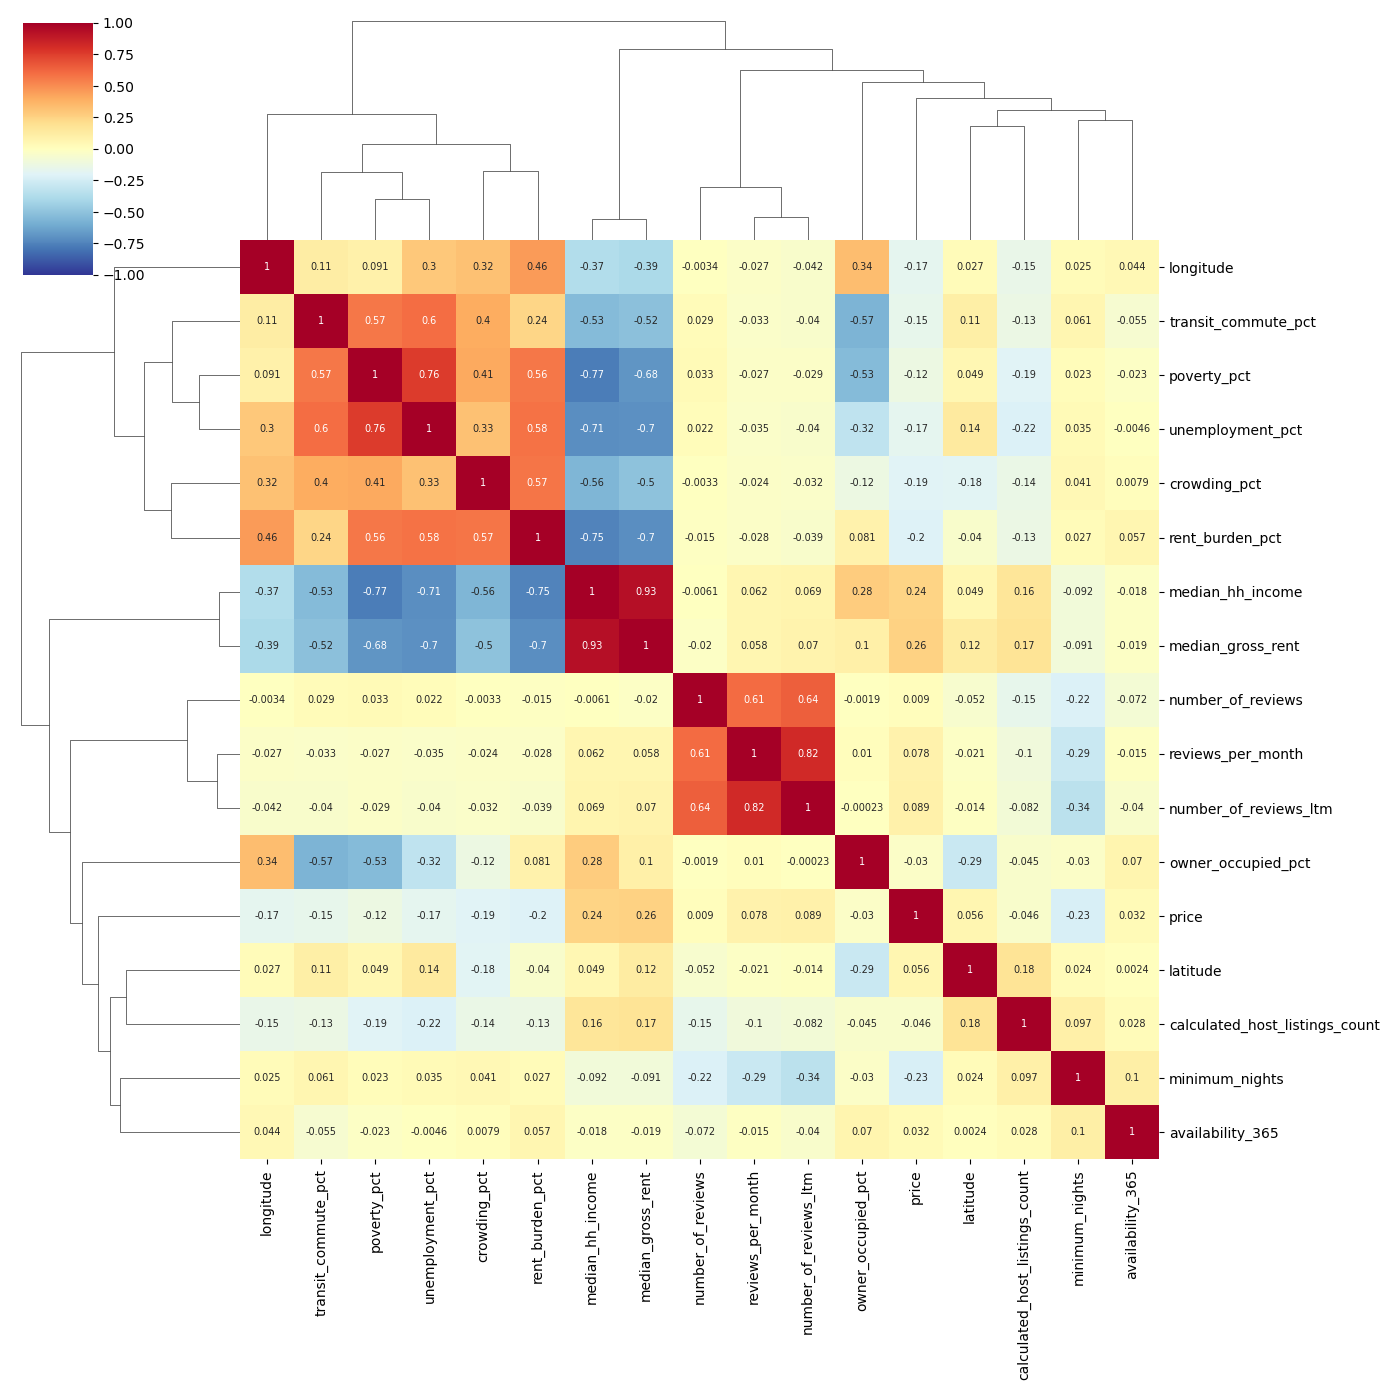

In [11]:
cor = NYC_st.corr()

sns.clustermap(cor, annot = True, cmap = 'RdYlBu_r',vmin = -1, vmax = 1,figsize=(14,14), annot_kws={'size': 7})
plt.show()

In [12]:
pca = PCA(random_state = 2000, n_components = None)
pca.fit_transform(NYC_st)

array([[-0.32416186, -0.72817655,  1.30921078, ...,  0.00877339,
        -0.0156919 ,  0.09579406],
       [ 1.74450409,  0.32895871, -0.87521184, ..., -0.2462927 ,
         0.00951267, -0.17902004],
       [-3.2011737 ,  0.7911836 , -1.63877992, ..., -0.30060654,
         0.31488041,  0.02218867],
       ...,
       [ 0.06295468, -1.01542055, -1.16788772, ..., -0.12873102,
         0.36571649,  0.02341257],
       [-1.02679876,  0.20663171,  1.32892524, ..., -0.25409217,
        -0.06776378, -0.27531096],
       [ 1.31943103, -0.39049234,  4.84191046, ..., -0.27102692,
         0.52807317,  0.13770669]], shape=(14286, 17))

In [13]:
pca.explained_variance_

array([4.99604696, 2.5938331 , 1.92534416, 1.14234723, 1.08149415,
       0.99856085, 0.86790884, 0.68990179, 0.66104031, 0.52522723,
       0.41434818, 0.30184033, 0.28959729, 0.17569286, 0.17330451,
       0.131524  , 0.03317827])

In [14]:
pca.explained_variance_ratio_

array([0.29386454, 0.15256774, 0.11324761, 0.06719219, 0.06361285,
       0.05873476, 0.05104989, 0.04057962, 0.038882  , 0.03089356,
       0.02437172, 0.01775407, 0.01703394, 0.01033415, 0.01019367,
       0.00773616, 0.00195153])

In [15]:
exp_variance_ratio = pca.explained_variance_ratio_

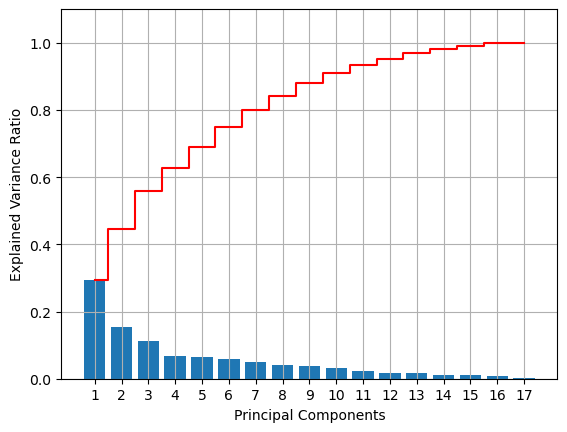

In [16]:
def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = range(1, len(exp_variance_ratio)+1)
    plt.bar(x_axis, exp_variance_ratio,
            align = 'center', label = 'Individual Explained Variance Ratio')
    plt.step(x_axis, np.cumsum(exp_variance_ratio),
             where = 'mid', color='red', label='Cumulative Explained Variance Ratio')
    plt.ylim(0, 1.1)
    plt.xticks(x_axis)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.grid()
    plt.show()

explained_variance_ratio_plot(exp_variance_ratio)

In [17]:
loadings = pca.components_

In [18]:
num_pc = pca.components_.shape[1]
pc_list = ["PC"+str(i) for i in list(range(1, num_pc+1))]

loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variable'] = NYC.columns.values
loadings_df = loadings_df.set_index('variable')
loadings_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17
variable,,,,,,,,,,,,,,,,,
latitude,0.001931,-0.040034,-0.341032,0.489245,0.475602,-0.304357,-0.240897,0.115785,0.008884,-0.355166,0.119080,-0.214433,-0.201495,-0.104969,-0.058917,0.104423,-0.009187
longitude,-0.184007,-0.009242,0.423913,0.207225,0.287081,-0.271594,-0.199482,0.335882,0.046396,0.366454,-0.066264,0.532017,0.026948,0.062307,0.027406,0.028221,0.067773
price,0.131697,0.091963,-0.139493,-0.403320,0.573454,0.119937,0.180139,0.022032,0.618281,0.174316,0.028057,-0.046849,-0.001214,-0.011630,-0.003833,-0.008845,-0.005811
minimum_nights,-0.048516,-0.309801,0.003315,0.313381,-0.357814,0.242512,-0.372274,-0.038919,0.674680,-0.043981,-0.110220,0.007009,0.061363,-0.012481,0.054797,0.015720,0.003258
number_of_reviews,0.003994,0.497757,0.018967,0.132879,-0.165402,0.028851,-0.137741,-0.052958,0.129350,0.147582,0.795889,0.009415,0.070261,0.057368,-0.056615,-0.027623,-0.001493
reviews_per_month,0.039728,0.546691,0.017487,0.182203,-0.047399,0.084719,0.005440,0.018449,0.097462,-0.067500,-0.447648,-0.018781,-0.030598,0.282036,-0.600572,-0.013983,-0.009651
calculated_host_listings_count,0.103951,-0.153768,-0.130588,0.535554,-0.054233,-0.078106,0.717420,-0.090789,0.093858,0.307648,0.034612,0.027686,0.138419,-0.033817,-0.047093,0.039619,-0.013766
availability_365,-0.002152,-0.064927,0.101088,0.251562,0.331325,0.847491,-0.040611,0.082538,-0.280313,0.042695,0.071713,0.009920,-0.000971,-0.007394,0.007934,0.005645,0.002915
number_of_reviews_ltm,0.045181,0.559986,0.003863,0.169197,-0.038853,0.047290,0.047016,0.005407,0.058134,-0.049277,-0.306097,0.010703,-0.018398,-0.342076,0.656547,0.041072,0.005747


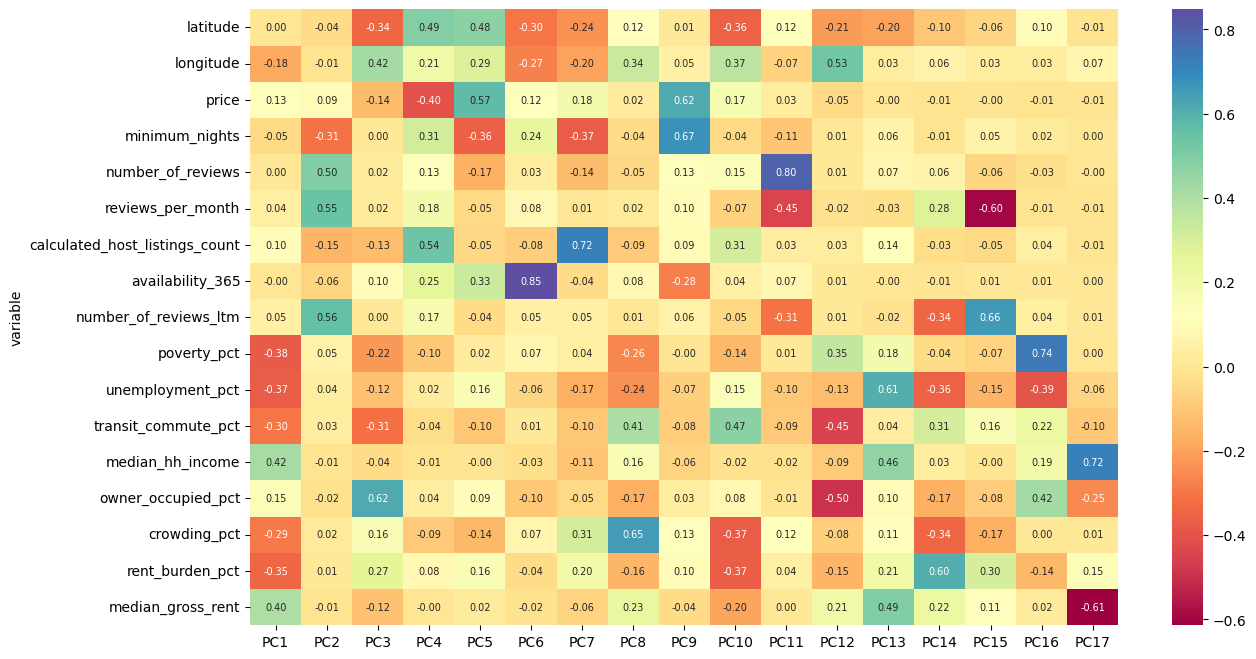

In [19]:
plt.figure(figsize=(14, 8))
ax = sns.heatmap(loadings_df, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='Spectral')
plt.show()
# can browse characteristics of each principal component

In [20]:
pca.transform(NYC_st)

array([[-0.32416186, -0.72817655,  1.30921078, ...,  0.00877339,
        -0.0156919 ,  0.09579406],
       [ 1.74450409,  0.32895871, -0.87521184, ..., -0.2462927 ,
         0.00951267, -0.17902004],
       [-3.2011737 ,  0.7911836 , -1.63877992, ..., -0.30060654,
         0.31488041,  0.02218867],
       ...,
       [ 0.06295468, -1.01542055, -1.16788772, ..., -0.12873102,
         0.36571649,  0.02341257],
       [-1.02679876,  0.20663171,  1.32892524, ..., -0.25409217,
        -0.06776378, -0.27531096],
       [ 1.31943103, -0.39049234,  4.84191046, ..., -0.27102692,
         0.52807317,  0.13770669]], shape=(14286, 17))

In [21]:
scores = pca.transform(NYC_st).transpose()

## PCA Observations
- 14,286 listings (those with `reviews_per_month` available) and 17 variables were used.
- PC1 explains about 29% of the variance and PC2 about 15%; the first 3 PCs reach about 56% and 6 PCs reach about 75%.
- PC1 is a neighborhood affluence axis: positive on `median_hh_income` and `median_gross_rent`, negative on `poverty_pct`, `unemployment_pct`, `rent_burden_pct` and `crowding_pct`.
- PC2 is a review-activity axis: loaded mainly by `number_of_reviews`, `reviews_per_month` and `number_of_reviews_ltm`.
- PC3 is mostly `owner_occupied_pct` and `longitude`, and PC4 mixes `calculated_host_listings_count`, `latitude` and `price`.